In [3]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('Titanic-Dataset.csv')

# Handle missing values
df = df.fillna({
    'Age': df['Age'].median(),
    'Cabin': 'Unknown',
    'Embarked': df['Embarked'].mode()[0]
})

# Feature extraction & encoding
df['Deck'] = df['Cabin'].str[0]
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# Drop non-numeric ID/text columns and one-hot encode categoricals
df_model = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
df_model = pd.get_dummies(df_model, columns=['Embarked', 'Deck'], drop_first=True, dtype=int)

# Separate predictors (X) and continuous target (y = Fare)
X = df_model.drop(columns=['Fare'])
y = df_model['Fare']

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")

Training samples: 712 | Testing samples: 179


In [5]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

print(f"Model Intercept: ${lr.intercept_:.2f}")

Model Intercept: $74.34


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = lr.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Mean Squared Error  (MSE): {mse:.2f}")
print(f"R² Score:                  {r2:.4f}")


Mean Absolute Error (MAE): $16.65
Mean Squared Error  (MSE): 677.00
R² Score:                  0.5625


   Feature  Coefficient
    Deck_B    62.383312
    Deck_C    53.562341
    Pclass   -23.977936
Embarked_S   -17.429303
    Deck_U    16.403751
    Deck_D    15.485603
Embarked_Q   -12.934958
    Deck_G    11.951759
    Deck_E    10.897040
     Parch     9.871579
    Deck_F     7.807452
     SibSp     5.863667
    Deck_T     4.983033
  Survived     4.681621
       Sex    -0.081683
       Age    -0.053749


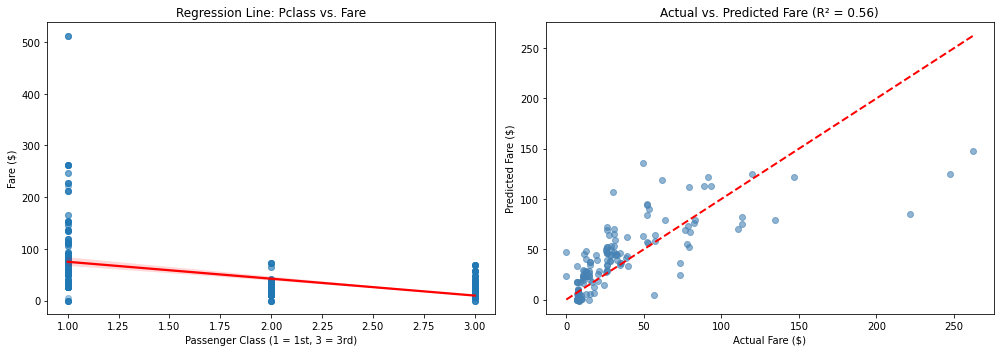

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Print sorted feature coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_
}).sort_values(by='Coefficient', key=abs, ascending=False)

print(coef_df.to_string(index=False))

# 2. Plot regression line (Pclass vs. Fare) & Actual vs. Predicted Fare
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Regression line showing Pclass vs. Fare
sns.regplot(
    x='Pclass', y='Fare', data=df_model, ax=axes[0],
    scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'}
)
axes[0].set_title('Regression Line: Pclass vs. Fare')
axes[0].set_xlabel('Passenger Class (1 = 1st, 3 = 3rd)')
axes[0].set_ylabel('Fare ($)')

# Right: Multiple Linear Regression Actual vs. Predicted
axes[1].scatter(y_test, y_pred, alpha=0.6, color='steelblue')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_title(f'Actual vs. Predicted Fare (R² = {r2:.2f})')
axes[1].set_xlabel('Actual Fare ($)')
axes[1].set_ylabel('Predicted Fare ($)')

plt.tight_layout()
plt.show()